# Hospital Readmission Risk Prediction Using MLP

# CBIM Problem Canvas – Hospital Readmission Risk Prediction Using MLP

| CBIM Component | Answer |
|---|---|
| **Situation (S)** | Hospitals treat patients with diabetes and discharge them after providing medical care. However, some patients return to the hospital within 30 days of discharge. Repeated hospital admissions increase healthcare costs and hospital resource utilization. |
| **Complication (C)** | Hospitals face difficulties in identifying patients who are at higher risk of readmission within 30 days. Without early identification, hospitals may not provide sufficient discharge planning, follow-up appointments, and post-discharge support. |
| **Question (Q)** | Can we develop a Deep Learning model using a Multi-Layer Perceptron (MLP) to predict whether a patient is likely to be readmitted within 30 days of discharge using historical hospital encounter data? |
| **SSOT (Single Source of Truth)** | Diabetes 130-US Hospitals Dataset containing approximately 101,766 patient encounters and 47 features, including patient information, admission details, medications and hospital encounter characteristics. |
| **Success Definition** | Develop an MLP model that predicts 30-day readmission risk, evaluates performance using Accuracy, Precision, Recall, F1-score and ROC-AUC, and identifies high-risk patients for additional follow-up support. |
| **Primary Stakeholder** | Hospital Management, Healthcare Administrators, Doctors and Medical Professionals, and Hospital Discharge Planning Teams. |

## Import Required Libraries



In [1]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings('ignore')

print("TensorFlow Version:", tf.__version__)

/Users/pinnamanenisaisubhash/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow Version: 2.20.0


In [2]:
df = pd.read_csv('/Users/pinnamanenisaisubhash/Documents/Deep Learning/diabetes+130-us+hospitals+for+years+1999-2008/diabetic_data.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Data Understanding

In [3]:
df.shape

(101766, 50)

In [4]:
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

In [5]:
df.head(5)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
df.tail(5)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [8]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [9]:
df.describe(include='object').T

,count,unique,top,freq
race,101766,6,Caucasian,76099
gender,101766,3,Female,54708
age,101766,10,[70-80),26068
weight,101766,10,?,98569
payer_code,101766,18,?,40256
medical_specialty,101766,73,?,49949
diag_1,101766,717,428,6862
diag_2,101766,749,276,6752
diag_3,101766,790,250,11555
max_glu_serum,5346,3,Norm,2597


In [10]:
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
# Replace ? with NaN
df.replace('?', np.nan, inplace=True)

# Missing value analysis
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report.head(5))

,Missing_Count,Missing_Percentage
weight,98569,96.858479
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322
medical_specialty,49949,49.082208
payer_code,40256,39.557416


In [13]:
# target variable analysis
print(df['readmitted'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


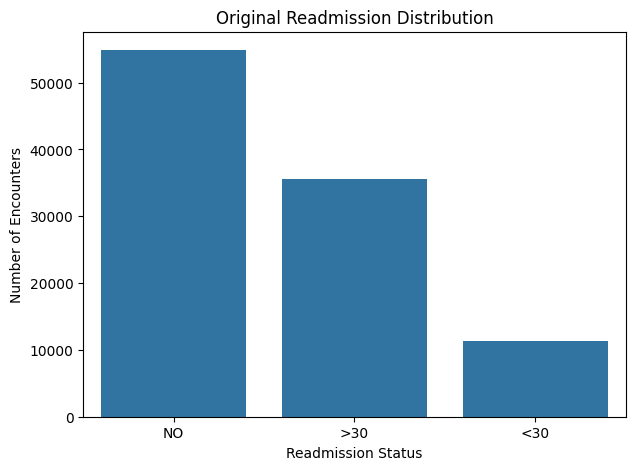

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='readmitted',
    order=['NO', '>30', '<30']
)

plt.title("Original Readmission Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Encounters")
plt.show()

In [15]:
# Convert target into binary classification
df['readmitted'] = df['readmitted'].map({
    '<30': 1,
    '>30': 0,
    'NO': 0
})

print(df['readmitted'].value_counts())

readmitted
0    90409
1    11357
Name: count, dtype: int64


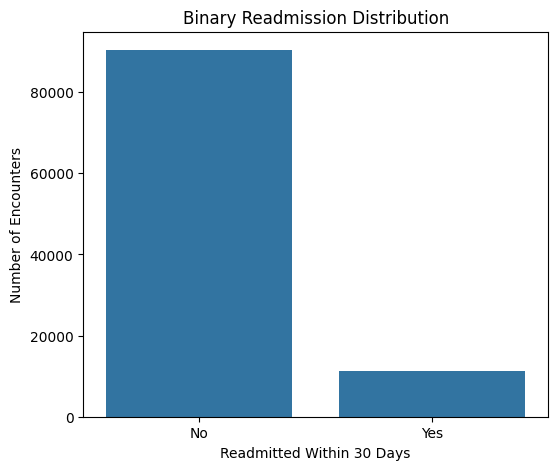

In [16]:
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='readmitted')

plt.title("Binary Readmission Distribution")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Number of Encounters")

plt.xticks([0, 1], ['No', 'Yes'])

plt.show()

In [17]:
print(
    df['readmitted']
    .value_counts(normalize=True) * 100
)

readmitted
0    88.840084
1    11.159916
Name: proportion, dtype: float64


In [18]:
print(
    df['readmitted']
    .value_counts(normalize=True) * 100
)

readmitted
0    88.840084
1    11.159916
Name: proportion, dtype: float64


In [19]:
df['patient_nbr'].nunique()

71518

# Exploratory Data Analysis (EDA)

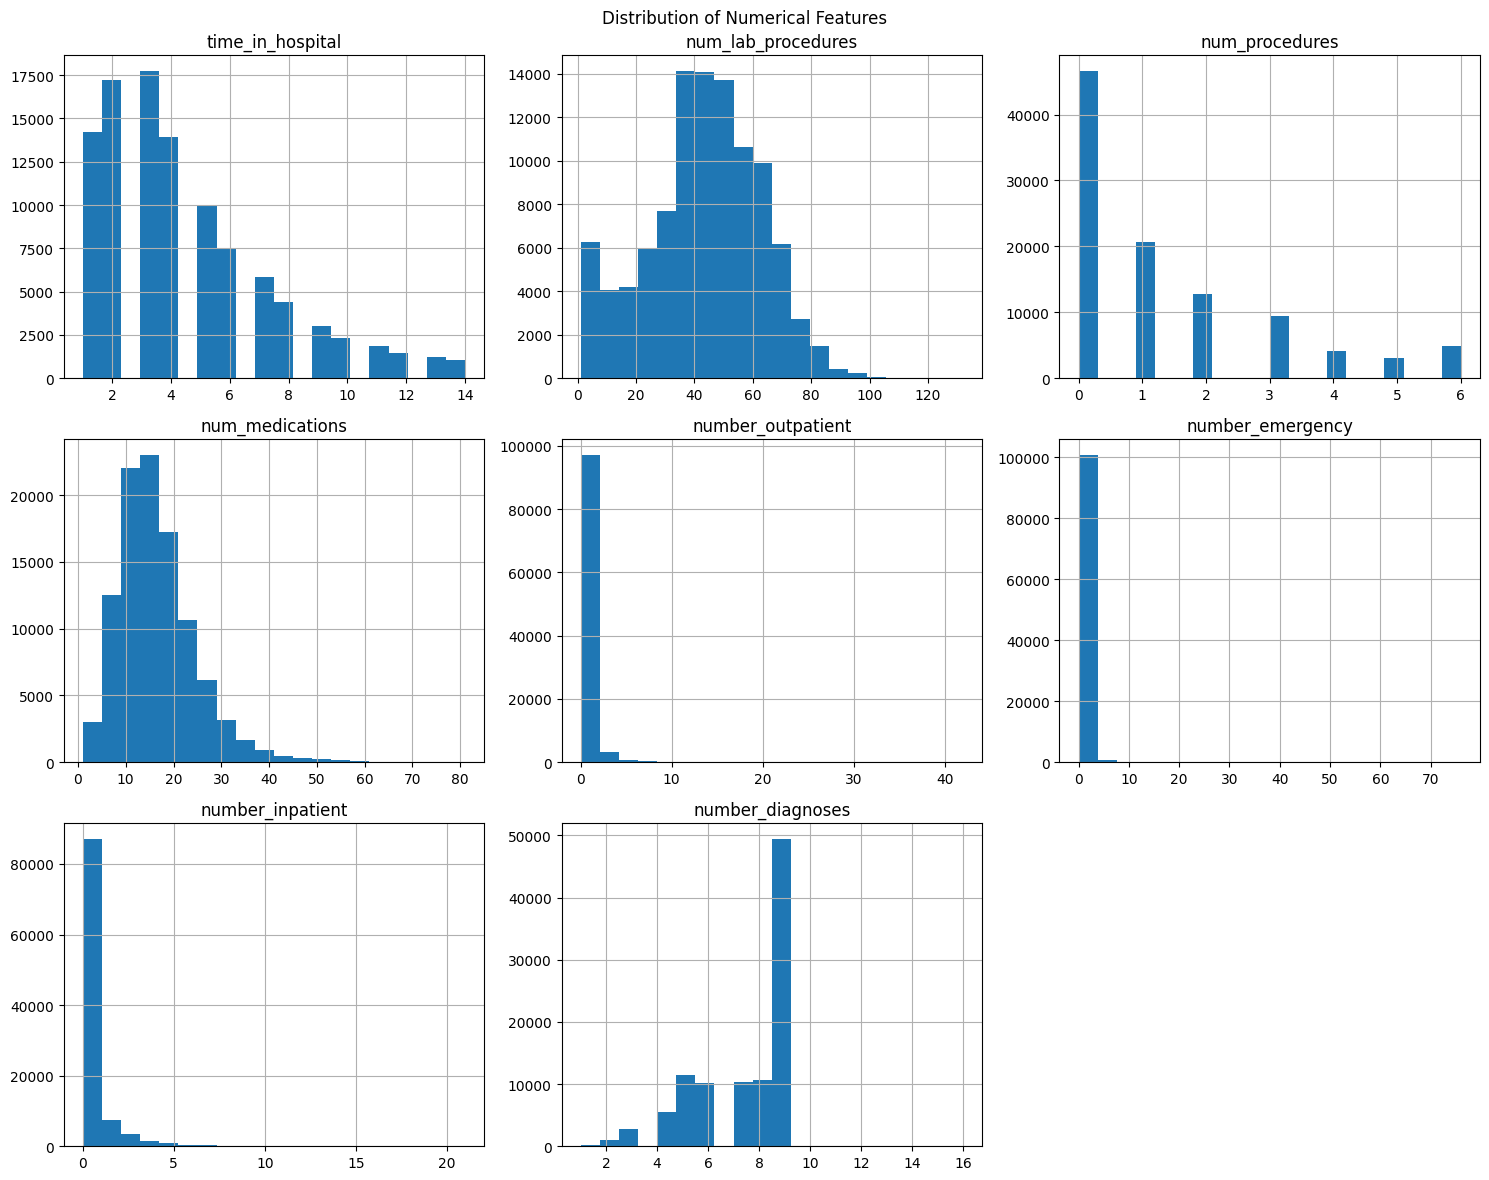

In [20]:
numerical_cols = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_outpatient',
    'number_emergency',
    'number_inpatient',
    'number_diagnoses'
]

df[numerical_cols].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

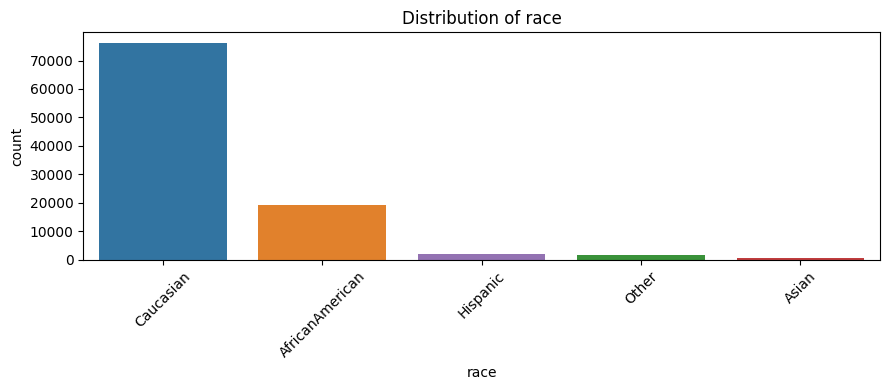

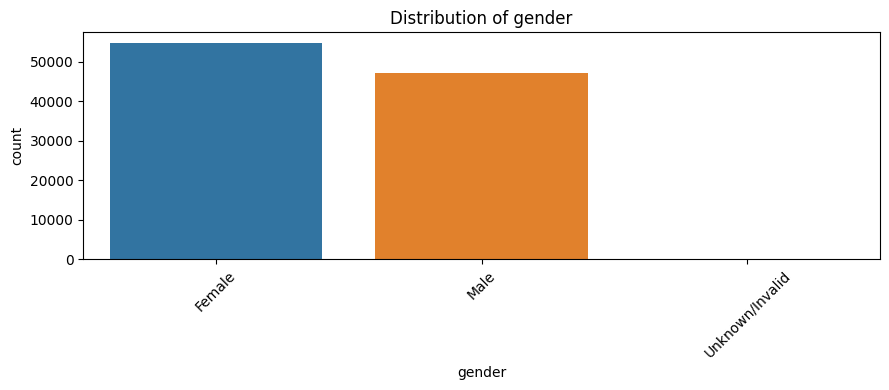

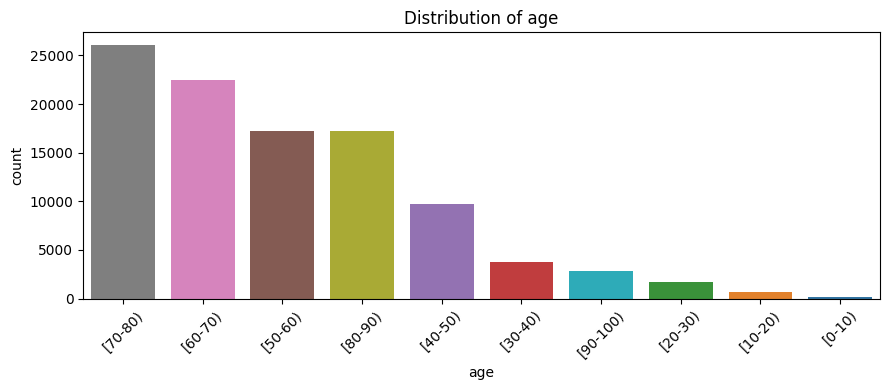

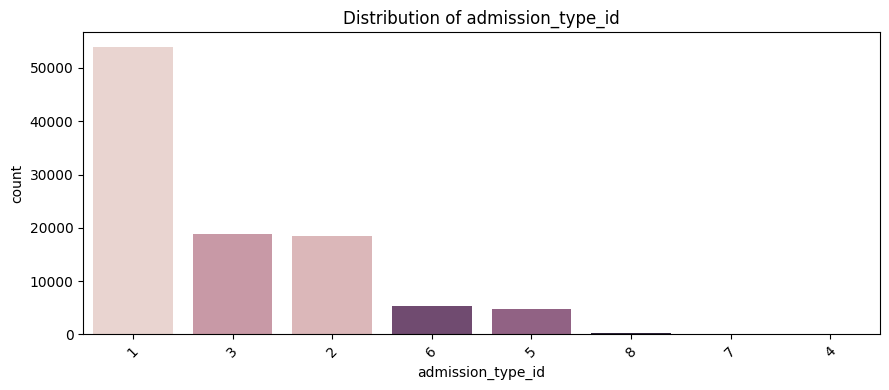

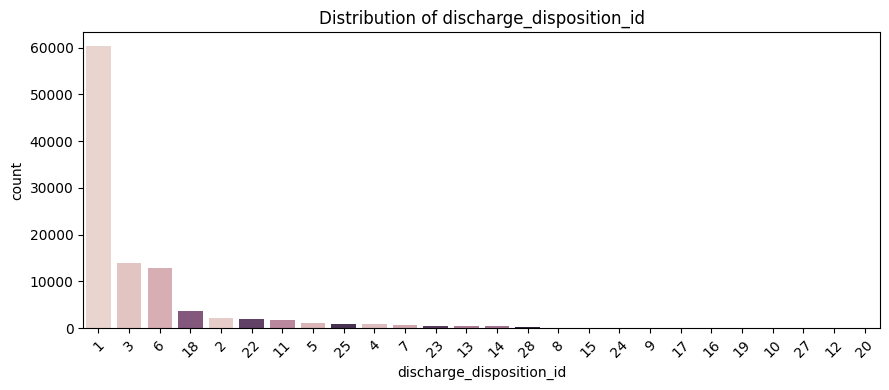

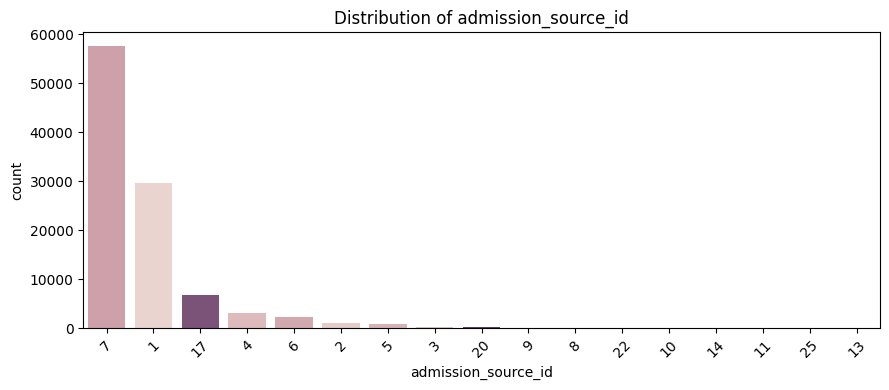

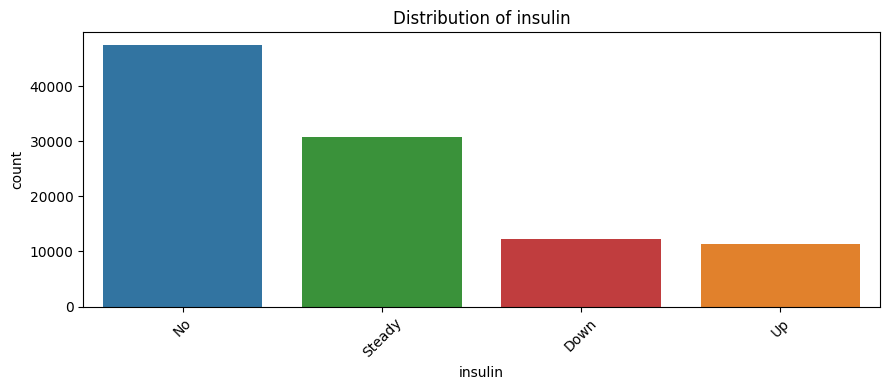

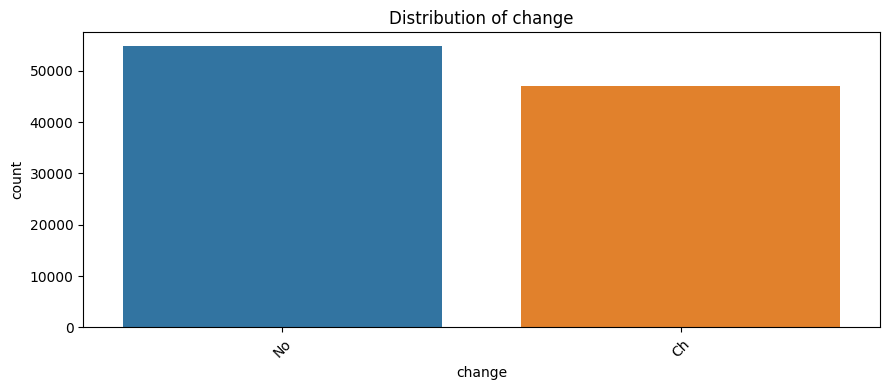

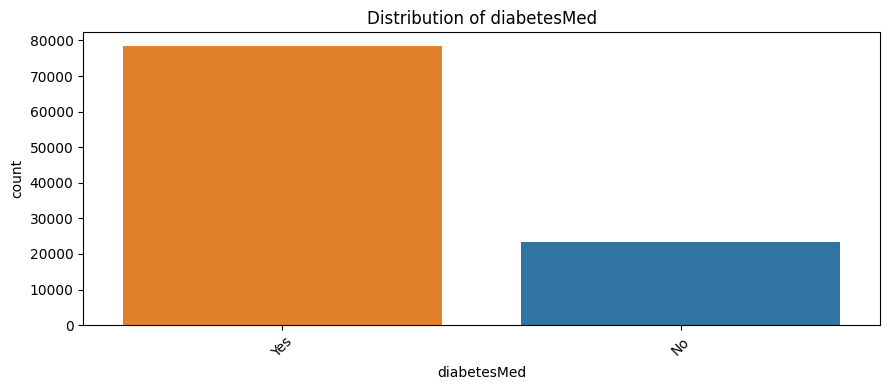

In [21]:
categorical_cols = [
    'race',
    'gender',
    'age',
    'admission_type_id',
    'discharge_disposition_id',
    'admission_source_id',
    'insulin',
    'change',
    'diabetesMed'
]

for col in categorical_cols:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index,
        hue=col,
        legend=False
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Age vs Readmission

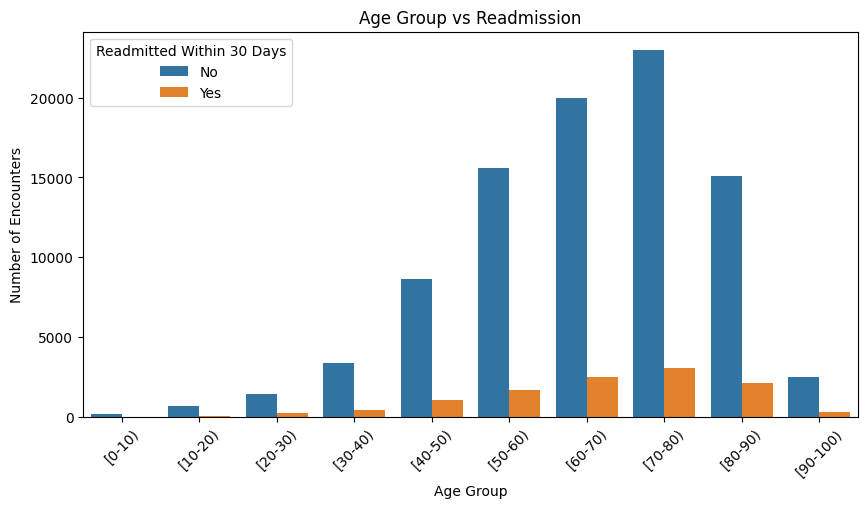

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='age',
    hue='readmitted'
)

plt.title("Age Group vs Readmission")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)

# Adding legend labels to represent mapped values
plt.legend(title='Readmitted Within 30 Days', labels=['No', 'Yes'])

plt.show()

## Hospital stay vs Readmission

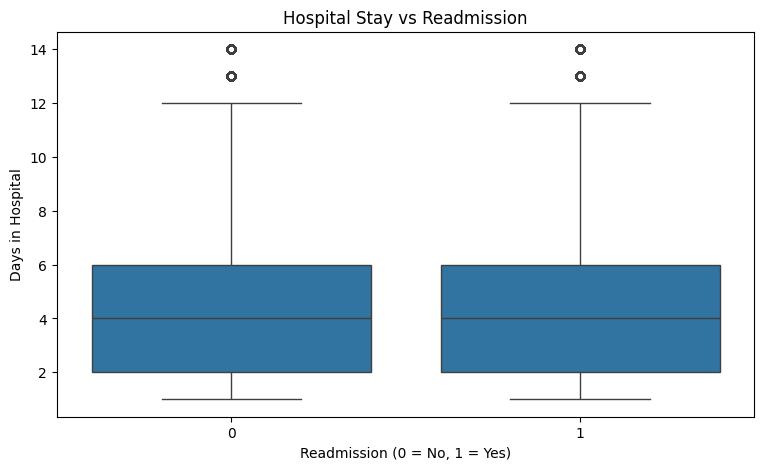

In [23]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='readmitted',
    y='time_in_hospital'
)

plt.title("Hospital Stay vs Readmission")
plt.xlabel("Readmission (0 = No, 1 = Yes)")
plt.ylabel("Days in Hospital")

plt.show()

## Previous inpatient visits vs Readmission

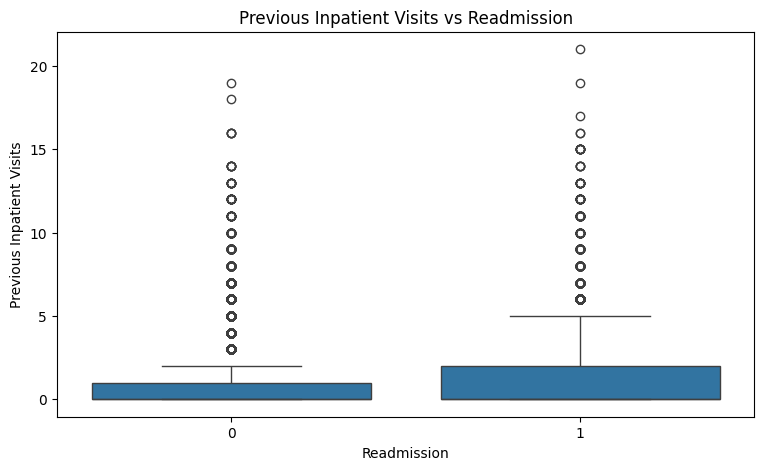

In [24]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='readmitted',
    y='number_inpatient'
)

plt.title("Previous Inpatient Visits vs Readmission")
plt.xlabel("Readmission")
plt.ylabel("Previous Inpatient Visits")

plt.show()

## Correlation analysis

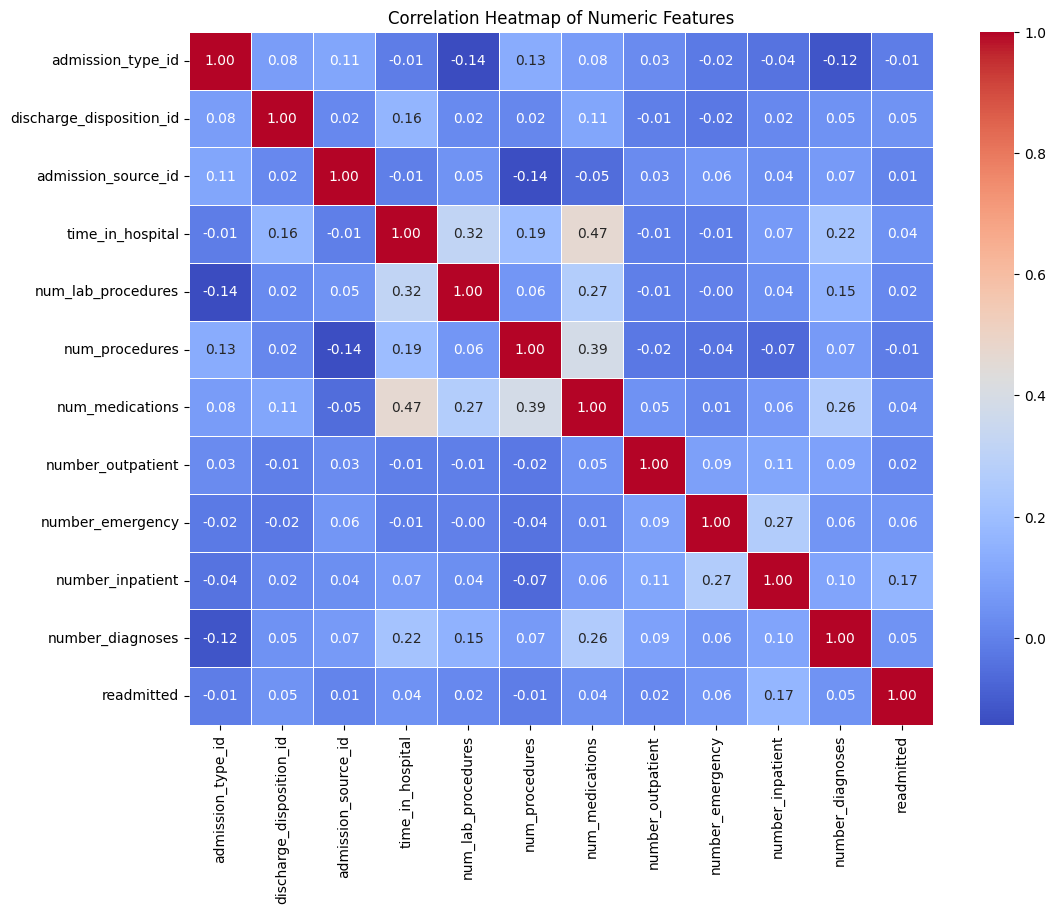

In [25]:
# Exclude non-informative patient/encounter ID columns for clean correlation analysis
numeric_df = df.select_dtypes(include=np.number).drop(columns=['encounter_id', 'patient_nbr'], errors='ignore')

correlation = numeric_df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Features")
plt.show()

## outliers detection

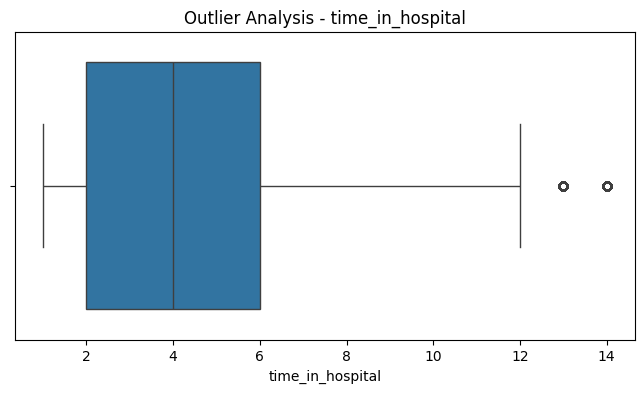

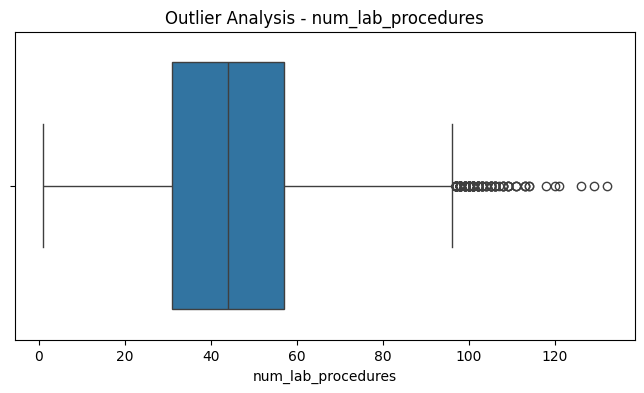

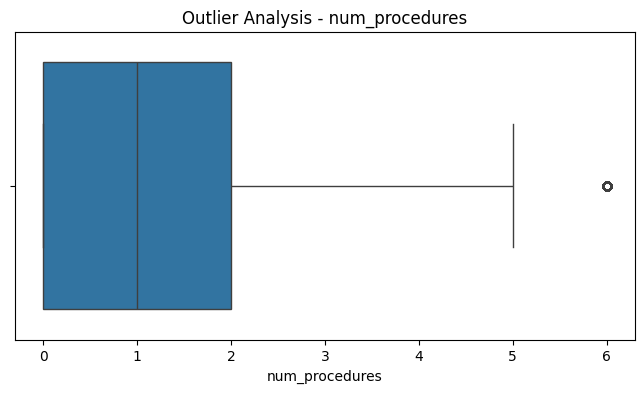

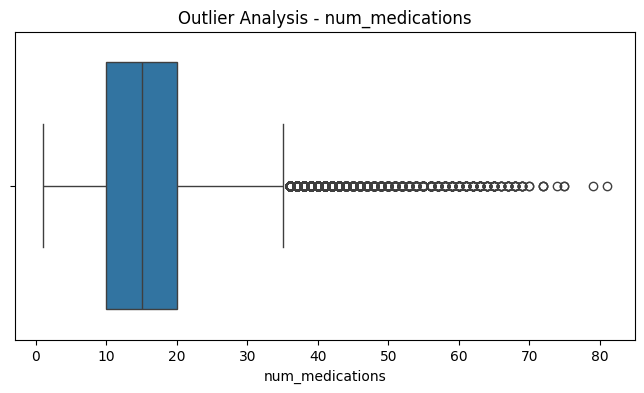

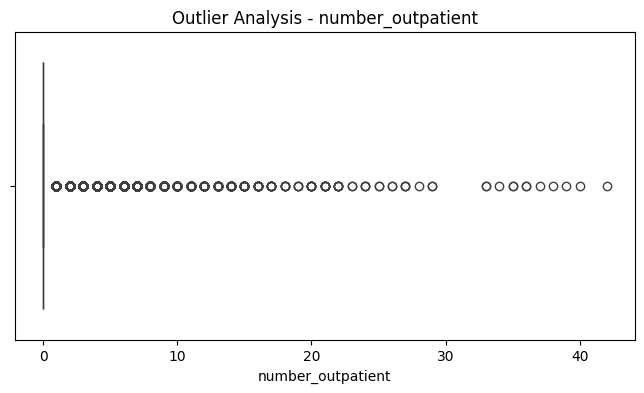

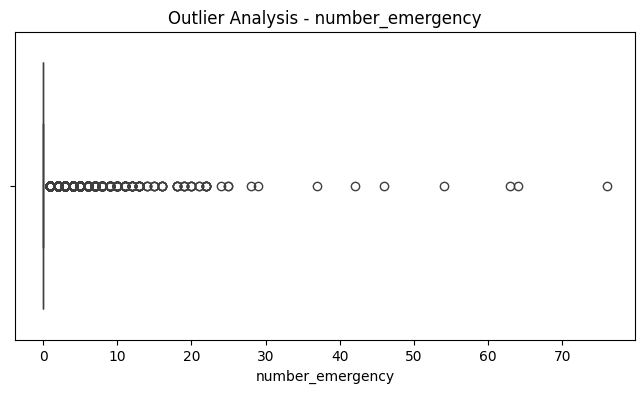

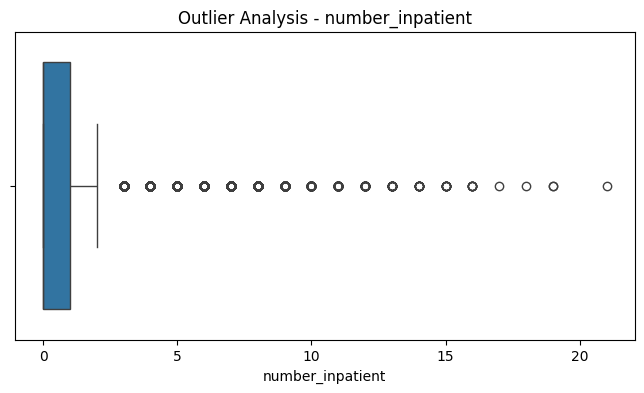

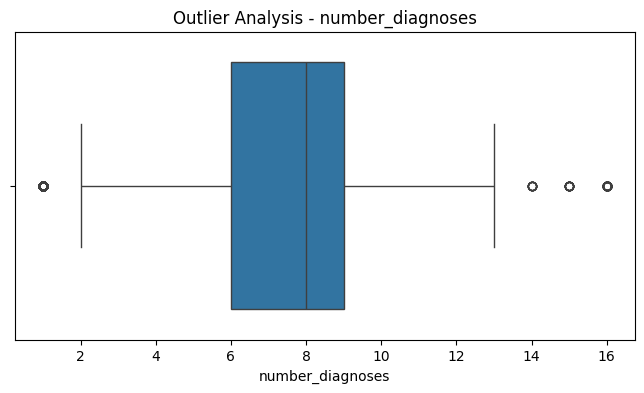

In [26]:
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Analysis - {col}")

    plt.show()

In [27]:
# Exclude patient and encounter identifiers
features_for_corr = numeric_df.drop(columns=['encounter_id', 'patient_nbr'],errors='ignore')

target_corr = features_for_corr.corr()['readmitted'].drop('readmitted').sort_values(ascending=False)

display(target_corr)

number_inpatient            0.165147
number_emergency            0.060747
discharge_disposition_id    0.050560
number_diagnoses            0.049524
time_in_hospital            0.044199
num_medications             0.038432
num_lab_procedures          0.020364
number_outpatient           0.018893
admission_source_id         0.005820
admission_type_id          -0.011651
num_procedures             -0.012227
Name: readmitted, dtype: float64

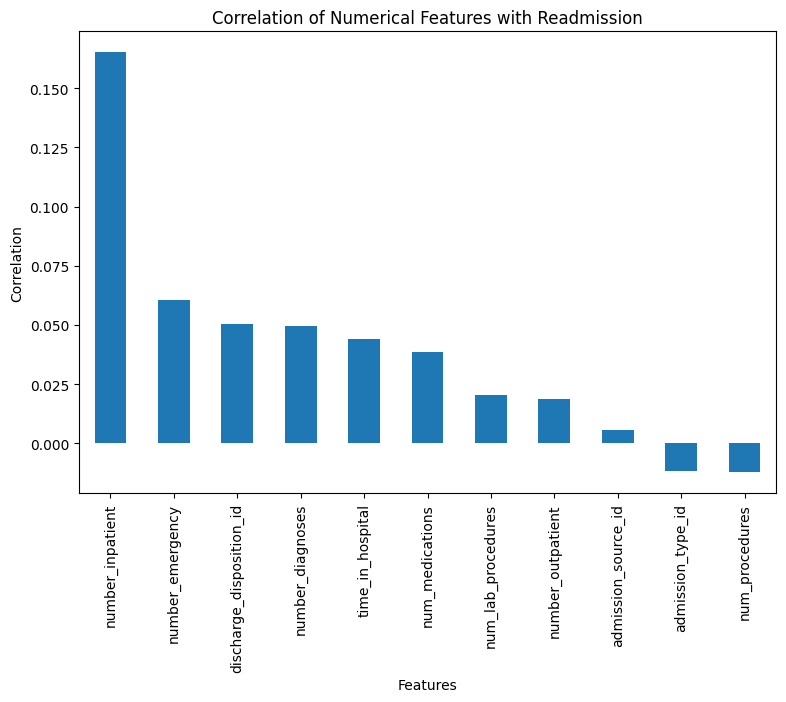

In [28]:
plt.figure(figsize=(9, 6))

target_corr.plot(kind='bar')

plt.title("Correlation of Numerical Features with Readmission")
plt.ylabel("Correlation")
plt.xlabel("Features")

plt.show()

# Feature Selection

In [29]:
# Keep patient ID for group-based splitting
groups = df["patient_nbr"].copy()

# Remove identifiers and high-missingness feature
drop_columns = [
    "encounter_id",
    "patient_nbr",
    "weight",
    "readmitted"
]

X = df.drop(columns=drop_columns)
y = df["readmitted"].astype(int)

# Remove columns containing only one unique value
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant Columns:", constant_columns)

X = X.drop(columns=constant_columns)

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Constant Columns: ['examide', 'citoglipton']
Feature Shape: (101766, 44)
Target Shape: (101766,)


# Identify numerical and categorical features

In [30]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print(numeric_features)
print(categorical_features)

Numerical Features: 11
Categorical Features: 33
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


##  Data Splitting

We divide the dataset into:

- Training: 70%
- Validation: 15%
- Testing: 15%



In [31]:
# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_temp = X.iloc[temp_idx]
y_temp = y.iloc[temp_idx]

groups_temp = groups.iloc[temp_idx]

# Second split: 15% validation, 15% test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(
        X_temp,
        y_temp,
        groups=groups_temp
    )
)

X_val = X_temp.iloc[val_idx]
y_val = y_temp.iloc[val_idx]

X_test = X_temp.iloc[test_idx]
y_test = y_temp.iloc[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (71520, 44)
Validation: (15027, 44)
Testing: (15219, 44)


In [32]:
train_patients = set(groups.iloc[train_idx])
val_patients = set(groups_temp.iloc[val_idx])
test_patients = set(groups_temp.iloc[test_idx])

print("Train-Val Overlap:", len(train_patients & val_patients))
print("Train-Test Overlap:", len(train_patients & test_patients))
print("Val-Test Overlap:", len(val_patients & test_patients))

Train-Val Overlap: 0
Train-Test Overlap: 0
Val-Test Overlap: 0


## Data Preprocessing


In [33]:
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=50,
            sparse_output=False,
            dtype=np.float32
        ))
    ]
)

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to float32
X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (71520, 649)
Validation Shape: (15027, 649)
Testing Shape: (15219, 649)


## Class Imbalance Handling



In [34]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class Weights:", class_weights)

Class Weights: {0: 0.5631584749366132, 1: 4.458296970452562}


# Multi-Layer Perceptron(MLP) Model Development

In [35]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Build MLP model

model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(X_train_processed.shape[1],)
    ),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        83,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,569 (365.50 KB)

 Trainable params: 93,569 (365.50 KB)

 Non-trainable params: 0 (0.00 B)

## Model Compilation



In [36]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]

)

print("Model Compiled Successfully!")

Model Compiled Successfully!


## Model Training



In [37]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(

    X_train_processed,
    y_train,

    validation_data=(
        X_val_processed,
        y_val
    ),

    epochs=30,

    batch_size=256,

    class_weight=class_weights,

    callbacks=[early_stopping],

    verbose=1

)

Epoch 1/30
280/280 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6206 - auc: 0.5963 - loss: 0.6720 - precision: 0.1432 - recall: 0.4963 - val_accuracy: 0.6167 - val_auc: 0.6359 - val_loss: 0.6570 - val_precision: 0.1570 - val_recall: 0.5670
Epoch 2/30
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6122 - auc: 0.6545 - loss: 0.6552 - precision: 0.1657 - recall: 0.6078 - val_accuracy: 0.4549 - val_auc: 0.6377 - val_loss: 0.7305 - val_precision: 0.1391 - val_recall: 0.7603
Epoch 3/30
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5984 - auc: 0.6724 - loss: 0.6484 - precision: 0.1701 - recall: 0.6549 - val_accuracy: 0.5554 - val_auc: 0.6402 - val_loss: 0.6676 - val_precision: 0.1505 - val_recall: 0.6534
Epoch 4/30
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6160 - auc: 0.6821 - loss: 0.6415 - precision: 0.1765 - recall: 0.6543 - val_accuracy: 0.5260 - val_auc: 0.6418 - val_loss: 0.6863 - val_precision: 0.1472 - val_recall: 0.6884
Epoch 5/30
280/280 ━━━━━━━━━━━━━

## Training Performance Visualization


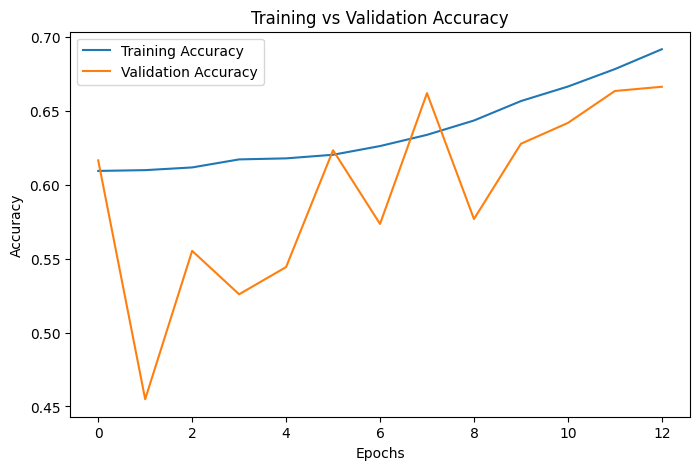

In [38]:
# Accuracy graph

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

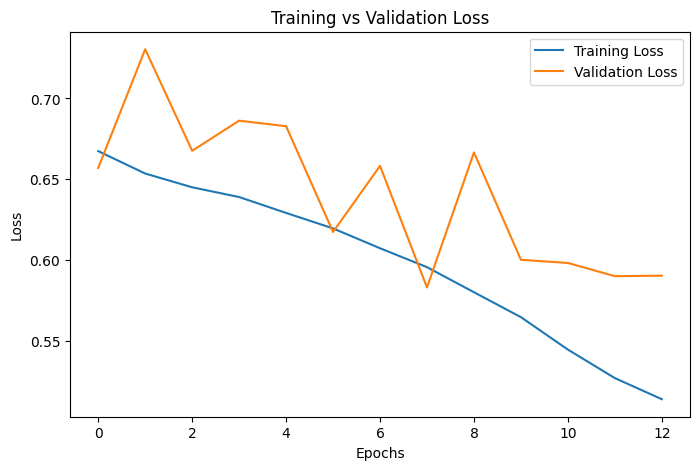

In [39]:
# Loss graph

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

##  Model Evaluation



In [40]:
# Predict probabilities

y_probability = model.predict(X_test_processed).flatten()

# Convert probabilities into binary predictions

threshold = 0.5

y_pred = (
    y_probability >= threshold
).astype(int)

print("Predictions completed!")

476/476 ━━━━━━━━━━━━━━━━━━━━ 0s 297us/step
Predictions completed!


##  Classification Metrics

We evaluate the model using:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. ROC-AUC



In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score,roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

val_probability = model.predict(X_val_processed).flatten()

threshold_results = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
        val_pred = (val_probability >= threshold).astype(int)

        threshold_results.append({
            "Threshold": threshold,
            "Precision": precision_score(y_val, val_pred, zero_division=0),
            "Recall": recall_score(y_val, val_pred, zero_division=0),
            "F1 Score": f1_score(y_val, val_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_val, val_probability)
        })


threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

470/470 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step


,Threshold,Precision,Recall,F1 Score,ROC-AUC
0,0.3,0.131338,0.789855,0.225226,0.626539
1,0.4,0.146276,0.657005,0.239279,0.626539
2,0.5,0.161118,0.490942,0.242614,0.626539
3,0.6,0.189545,0.304348,0.233604,0.626539
4,0.7,0.263288,0.128623,0.172819,0.626539


In [42]:
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.5


In [43]:
y_probability = model.predict(
    X_test_processed
).flatten()

y_pred = (
    y_probability >= best_threshold
).astype(int)

476/476 ━━━━━━━━━━━━━━━━━━━━ 0s 238us/step


In [44]:
# Calculate evaluation metrics

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

# Display results

results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]

})

print(results)

      Metric     Score
0   Accuracy  0.663907
1  Precision  0.166051
2     Recall  0.508333
3   F1 Score  0.250330
4    ROC-AUC  0.646125


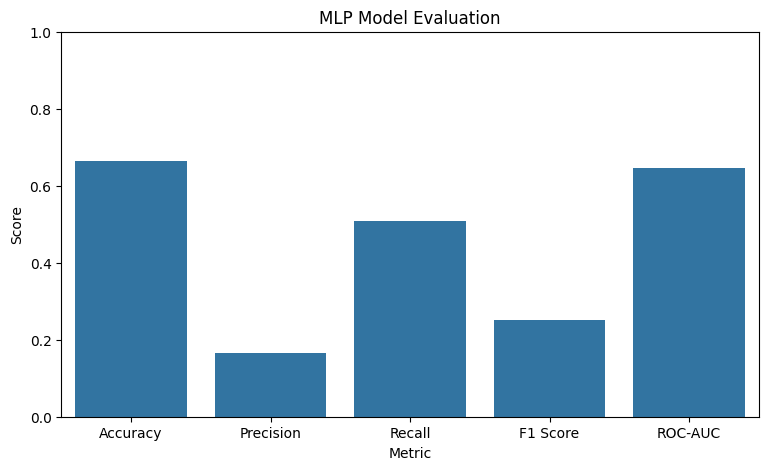

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Metric",
    y="Score"
)

plt.title("MLP Model Evaluation")
plt.ylim(0, 1)
plt.show()

##  Confusion Matrix

A confusion matrix compares actual labels
with predicted labels.

It contains:

True Positive (TP):
Actual readmitted and predicted readmitted.

True Negative (TN):
Actual not readmitted and predicted not readmitted.

False Positive (FP):
Actual not readmitted but predicted readmitted.

False Negative (FN):
Actual readmitted but predicted not readmitted.

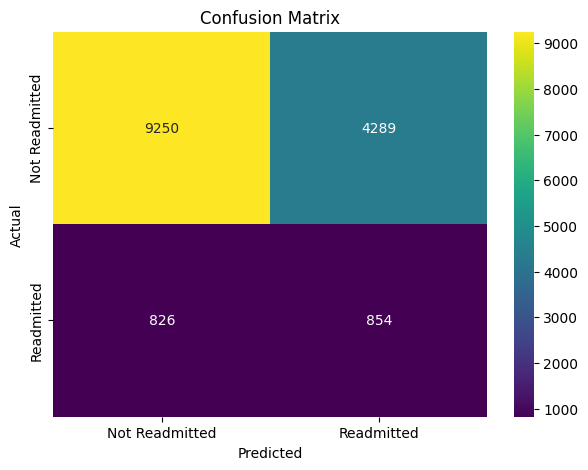

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    xticklabels=[
        "Not Readmitted",
        "Readmitted"
    ],
    yticklabels=[
        "Not Readmitted",
        "Readmitted"
    ]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [47]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Not Readmitted",
            "Readmitted"
        ],
        zero_division=0
    )
)

                precision    recall  f1-score   support

Not Readmitted       0.92      0.68      0.78     13539
    Readmitted       0.17      0.51      0.25      1680

      accuracy                           0.66     15219
     macro avg       0.54      0.60      0.52     15219
  weighted avg       0.84      0.66      0.72     15219



##  ROC Curve

The ROC curve evaluates how well the model
distinguishes between readmitted and non-readmitted
patients across different classification thresholds.

AUC represents the Area Under the Curve.

A higher AUC generally indicates better
discrimination between the two classes.



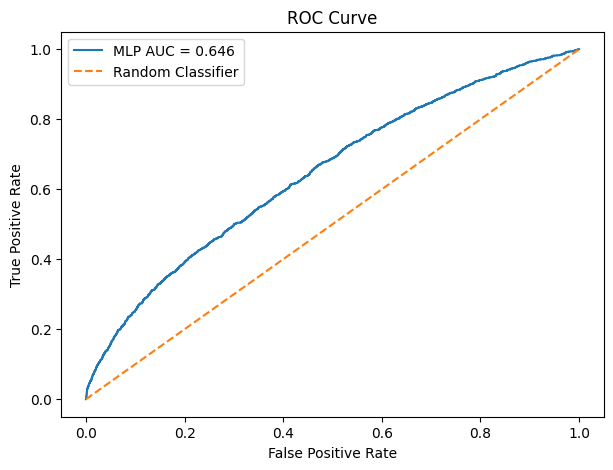

In [48]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"MLP AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.show()

## Structured Error Analysis

We analyse two major types of prediction errors.

1. False Positives
2. False Negatives

False Positive:
The model predicts that a patient will be readmitted,
but the actual outcome is not readmitted.

False Negative:
The model predicts that a patient will not be readmitted,
but the actual outcome is readmitted.


In [49]:
# Create patient-level error analysis dataset

patient_error_analysis = df.loc[
    X_test.index
].copy()

# Add actual and predicted values

patient_error_analysis["Actual"] = y_test.values

patient_error_analysis["Predicted"] = y_pred

patient_error_analysis["Risk_Probability"] = y_probability

# Identify error types

patient_error_analysis["Error_Type"] = np.select(
    [
        (patient_error_analysis["Actual"] == 1) &
        (patient_error_analysis["Predicted"] == 1),

        (patient_error_analysis["Actual"] == 0) &
        (patient_error_analysis["Predicted"] == 0),

        (patient_error_analysis["Actual"] == 0) &
        (patient_error_analysis["Predicted"] == 1),

        (patient_error_analysis["Actual"] == 1) &
        (patient_error_analysis["Predicted"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

print("Patient Error Analysis Created")

display(patient_error_analysis.head())

Patient Error Analysis Created


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,Actual,Predicted,Risk_Probability,Error_Type
22,182796,63000108,AfricanAmerican,Female,[70-80),NaN,2,1,4,2,...,No,No,No,No,No,0,0,0,0.378885,True Negative
32,260166,80845353,Caucasian,Female,[70-80),NaN,1,1,7,6,...,No,No,No,No,Yes,0,0,1,0.575605,False Positive
45,464994,106936875,Caucasian,Female,[40-50),NaN,3,1,2,2,...,No,No,No,No,Yes,0,0,0,0.259476,True Negative
48,537834,90097839,Caucasian,Male,[50-60),NaN,3,1,2,6,...,No,No,No,Ch,Yes,0,0,0,0.427298,True Negative
53,591996,58497651,AfricanAmerican,Female,[50-60),NaN,1,1,7,1,...,No,No,No,Ch,Yes,0,0,0,0.174346,True Negative


In [50]:
# Create patient-level prediction report

prediction_report = pd.DataFrame({
    "Encounter_ID": df.loc[y_test.index, "encounter_id"].values,
    "Actual_Readmission": y_test.values,
    "Predicted_Readmission": y_pred,
    "Risk_Probability": y_probability
})

# Convert binary labels into readable values

prediction_report["Actual_Readmission"] = (
    prediction_report["Actual_Readmission"]
    .map({
        1: "Yes",
        0: "No"
    })
)

prediction_report["Predicted_Readmission"] = (
    prediction_report["Predicted_Readmission"]
    .map({
        1: "Yes",
        0: "No"
    })
)

prediction_report["Risk_Probability"] = (
    prediction_report["Risk_Probability"].round(4)
)

# Display first 10 predictions

display(prediction_report.head(10))

print("Total test encounters:", len(prediction_report))

,Encounter_ID,Actual_Readmission,Predicted_Readmission,Risk_Probability
0,182796,No,No,0.3789
1,260166,No,Yes,0.5756
2,464994,No,No,0.2595
3,537834,No,No,0.4273
4,591996,No,No,0.1743
5,630342,No,Yes,0.6578
6,676416,No,Yes,0.6530
7,1069716,No,No,0.4578
8,1136472,No,No,0.4095
9,1185942,No,Yes,0.5914


Total test encounters: 15219


In [51]:
# Separate incorrect predictions

patient_error_analysis["Error_Type"] = np.select(
    [
        (patient_error_analysis["Actual"] == 1) & (patient_error_analysis["Predicted"] == 1),
        (patient_error_analysis["Actual"] == 0) & (patient_error_analysis["Predicted"] == 0),
        (patient_error_analysis["Actual"] == 0) & (patient_error_analysis["Predicted"] == 1),
        (patient_error_analysis["Actual"] == 1) & (patient_error_analysis["Predicted"] == 0),
    ],
    ["True Positive", "True Negative", "False Positive", "False Negative"],
    default="Unknown"
)

false_positives = patient_error_analysis[
    patient_error_analysis["Error_Type"] == "False Positive"
].copy()

false_negatives = patient_error_analysis[
    patient_error_analysis["Error_Type"] == "False Negative"
].copy()

# Separate correct predictions

true_positives = patient_error_analysis[
    patient_error_analysis["Error_Type"] == "True Positive"
].copy()

true_negatives = patient_error_analysis[
    patient_error_analysis["Error_Type"] == "True Negative"
].copy()

# Print counts

print("TRUE POSITIVES:", len(true_positives))
print("TRUE NEGATIVES:", len(true_negatives))
print("FALSE POSITIVES:", len(false_positives))
print("FALSE NEGATIVES:", len(false_negatives))

TRUE POSITIVES: 854
TRUE NEGATIVES: 9250
FALSE POSITIVES: 4289
FALSE NEGATIVES: 826


In [52]:
error_summary = (
    patient_error_analysis["Error_Type"]
    .value_counts()
    .reset_index()
)

error_summary.columns = [
    "Error_Type",
    "Count"
]

error_summary["Percentage"] = (
    error_summary["Count"] /
    len(patient_error_analysis) * 100
).round(2)

display(error_summary)

,Error_Type,Count,Percentage
0,True Negative,9250,60.78
1,False Positive,4289,28.18
2,True Positive,854,5.61
3,False Negative,826,5.43


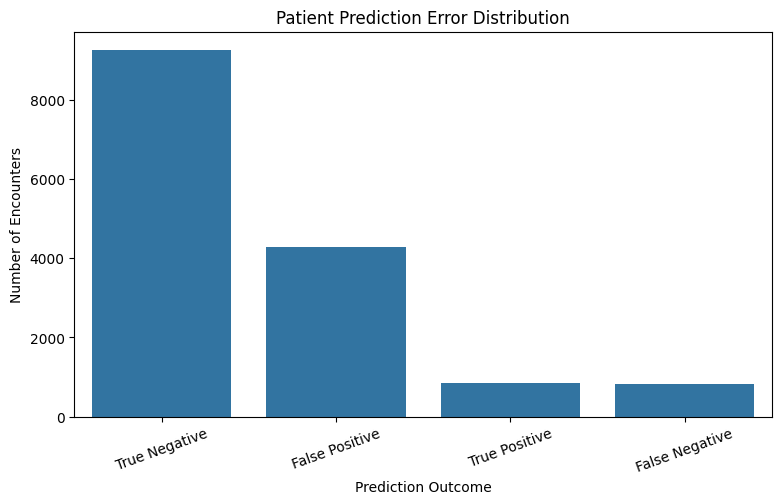

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=error_summary,
    x="Error_Type",
    y="Count"
)

plt.title("Patient Prediction Error Distribution")
plt.xlabel("Prediction Outcome")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=20)

plt.show()

 ## False Negative Patient Analysis

In [54]:
# Select relevant patient features

patient_features = [
    "patient_nbr",
    "encounter_id",
    "age",
    "gender",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

# Keep only columns available in the dataset

available_features = [
    col for col in patient_features
    if col in false_negatives.columns
]

# Display false negative patients

fn_patient_report = false_negatives[
    available_features + [
        "Actual",
        "Predicted",
        "Risk_Probability"
    ]
]

display(fn_patient_report.head(5))

,patient_nbr,encounter_id,age,gender,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,Actual,Predicted,Risk_Probability
116,3115566,1881372,[60-70),Male,4,65,2,19,0,0,0,7,1,0,0.329840
162,80499960,2521974,[80-90),Male,5,47,1,6,0,0,0,5,1,0,0.182747
444,34568172,3977208,[80-90),Male,3,56,2,26,0,0,0,5,1,0,0.254145
657,51738111,5184162,[70-80),Female,6,74,5,41,0,0,0,9,1,0,0.450995
699,59859657,5335140,[50-60),Female,2,44,4,14,0,0,0,9,1,0,0.298284


## False Positive Patient Analysis

In [55]:
# Display false positive patient characteristics

fp_patient_report = false_positives[
    available_features + [
        "Actual",
        "Predicted",
        "Risk_Probability"
    ]
]

display(fp_patient_report.head(5))

,patient_nbr,encounter_id,age,gender,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,Actual,Predicted,Risk_Probability
32,80845353,260166,[70-80),Female,6,27,0,16,0,0,0,8,0,1,0.575605
56,93232917,630342,[50-60),Female,9,37,2,19,0,0,1,4,0,1,0.657805
59,71778564,676416,[70-80),Male,7,2,1,8,0,0,1,5,0,1,0.652962
91,54746082,1185942,[70-80),Male,8,47,3,21,0,0,1,9,0,1,0.591410
92,91370916,1186980,[40-50),Male,4,27,0,12,0,0,1,5,0,1,0.603442


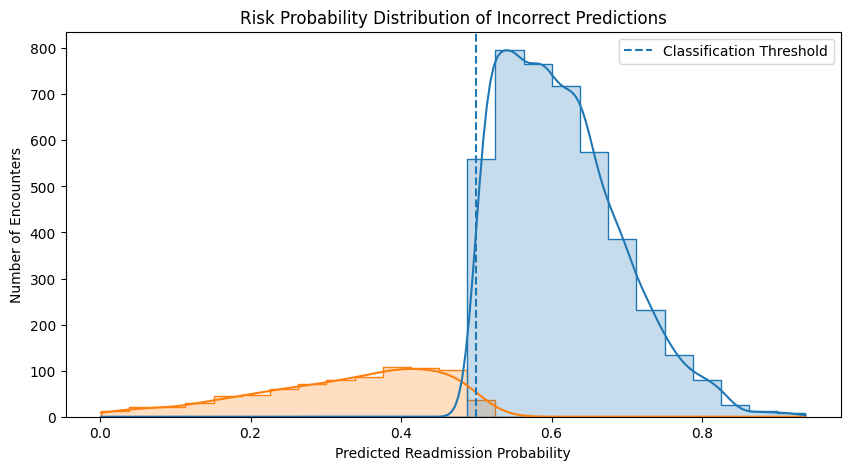

In [56]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=patient_error_analysis[
        patient_error_analysis["Error_Type"].isin(
            ["False Positive", "False Negative"]
        )
    ],
    x="Risk_Probability",
    hue="Error_Type",
    bins=25,
    kde=True,
    element="step"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Classification Threshold"
)

plt.title("Risk Probability Distribution of Incorrect Predictions")
plt.xlabel("Predicted Readmission Probability")
plt.ylabel("Number of Encounters")
plt.legend()

plt.show()

In [57]:
# Lowest probability false negative cases

low_risk_false_negatives = (
    false_negatives
    .sort_values("Risk_Probability")
)

display(
    low_risk_false_negatives[
        available_features + ["Risk_Probability"]
    ].head(5)
)

,patient_nbr,encounter_id,age,gender,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,Risk_Probability
67835,50110686,190709730,[40-50),Male,1,31,0,11,0,0,0,9,0.001226
91759,85297239,313683242,[60-70),Male,2,31,0,14,0,0,0,7,0.001733
19696,5607324,69931848,[50-60),Male,1,10,4,17,0,0,0,3,0.002753
86480,98482635,275028468,[70-80),Male,1,1,0,11,0,0,0,8,0.006525
21580,24029361,75060360,[50-60),Female,11,26,6,34,5,0,0,9,0.007365


In [58]:
# Calculate false positive and false negative rates

total_actual_positive = (
    patient_error_analysis["Actual"] == 1
).sum()

total_actual_negative = (
    patient_error_analysis["Actual"] == 0
).sum()

fn_rate = (
    len(false_negatives) /
    total_actual_positive
) * 100

fp_rate = (
    len(false_positives) /
    total_actual_negative
) * 100

print("False Negative Rate:", round(fn_rate, 2), "%")

print("False Positive Rate:", round(fp_rate, 2), "%")

False Negative Rate: 49.17 %
False Positive Rate: 31.68 %


In [59]:
# Final structured error analysis report

structured_error_report = pd.DataFrame({

    "Error_Type": [
        "False Positive",
        "False Negative"
    ],

    "Count": [
        len(false_positives),
        len(false_negatives)
    ],

    "Business_Impact": [
        "Additional follow-up resources may be used",
        "Potential high-risk patients may be missed"
    ],

    "Recommended_Action": [
        "Review risk thresholds and patient characteristics",
        "Improve recall and investigate missed patients"
    ]

})

display(structured_error_report)

,Error_Type,Count,Business_Impact,Recommended_Action
0,False Positive,4289,Additional follow-up resources may be used,Review risk thresholds and patient characteris...
1,False Negative,826,Potential high-risk patients may be missed,Improve recall and investigate missed patients


In [60]:
import os

os.makedirs("outputs", exist_ok=True)

In [61]:
# Save patient-level error analysis

patient_error_analysis.to_csv(
    "outputs/structured_patient_error_analysis.csv",
    index=False
)

# Save false negative report

false_negatives.to_csv(
    "outputs/false_negative_patients.csv",
    index=False
)

# Save false positive report

false_positives.to_csv(
    "outputs/false_positive_patients.csv",
    index=False
)

print("Structured error analysis reports saved!")

Structured error analysis reports saved!


In [62]:
# Identify patients with risk probability >= 0.70

high_risk_patients = prediction_report[
    prediction_report["Risk_Probability"] >= 0.70
]

print("High Risk Patients:", len(high_risk_patients))

high_risk_patients.head(10)

High Risk Patients: 849


,Encounter_ID,Actual_Readmission,Predicted_Readmission,Risk_Probability
61,4066842,No,Yes,0.8004
63,4086876,No,Yes,0.7032
85,5056230,No,Yes,0.7373
99,5505486,No,Yes,0.7614
116,6320778,Yes,Yes,0.7261
164,8565288,No,Yes,0.7470
181,9118542,No,Yes,0.7431
186,9251970,No,Yes,0.7059
197,9592686,Yes,Yes,0.7815
233,10739064,No,Yes,0.7486


# Model Evaluation Results, Error Analysis and Business Findings

##  Model Evaluation

The MLP model achieved the following results on the test dataset:

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 66.39% |
| Precision | 16.61% |
| Recall | 50.83% |
| F1-score | 25.03% |
| ROC-AUC | 0.6461 |

The model correctly classified approximately 66.39% of test encounters. However, its precision and recall indicate limited performance in identifying patients who will be readmitted within 30 days.

##  Confusion Matrix Analysis

The confusion matrix identified:

| Prediction Type | Count |
|---|---:|
| True Positives | 854 |
| True Negatives | 9,250 |
| False Positives | 4,289 |
| False Negatives | 826 |

### Interpretation

- **True Positive:** 854 actual readmissions were correctly identified.
- **True Negative:** 9,250 non-readmissions were correctly identified.
- **False Positive:** 4,289 encounters were incorrectly classified as readmissions.
- **False Negative:** 826 actual readmissions were missed by the model.

## Structured Error Analysis

### False Positive Analysis

The model incorrectly classified 4,289 encounters as readmissions.

These predictions may increase unnecessary follow-up workload and resource utilization.

**Recommended actions:**
- Review false-positive patient characteristics.
- Optimize classification thresholds.
- Improve precision while maintaining an acceptable recall level.

### False Negative Analysis

The model missed 826 actual readmissions.

This is an important business concern because patients who could benefit from additional post-discharge support may remain unidentified.

**Recommended actions:**
- Investigate false-negative patient characteristics.
- Improve minority-class detection.
- Experiment with classification thresholds using validation data.
- Improve patient risk identification.

##  Business Findings

1. Previous inpatient admissions and emergency visits can be investigated to understand patient readmission patterns.
2. The model demonstrates limited ability to identify actual readmissions.
3. False-negative predictions highlight opportunities to improve patient identification and discharge planning.
4. Risk probability scores could help prioritize follow-up reviews after further validation.
5. Additional model optimization and more recent healthcare data are required.

## 5. Business Recommendations

- Investigate methods to improve minority-class detection.
- Experiment with classification thresholds using validation data.
- Analyze false-negative patient characteristics.
- Improve model discrimination and generalization.
- Validate the model using recent healthcare records.

## Conclusion

The MLP model demonstrates the potential application of deep learning for hospital readmission risk prediction.

The model achieved 66.39% accuracy, 16.61% precision, 50.83% recall, 25.03% F1-score and 0.6461 ROC-AUC on the test dataset.

The structured error analysis identified 826 false negatives and 4,289 false positives, highlighting the need for further improvements in patient risk identification.

Threshold optimization, improved class imbalance handling, better feature selection and more recent healthcare data may help improve future model performance.

This project demonstrates how deep learning can be applied to healthcare analytics to support patient risk assessment and post-discharge planning.

